# E4a — 图7 内核吞吐(flush + decode 步,A3 口径)

论文图7 在 GPU(B200/PRO6000/5090)上测 int8-payload 读出内核,
**2.4–4.3×**(B=512)——绝对数字在 A3 不可复现(见 PAPER_REPRO 口径
声明 1)。A3 复测覆盖当前已落地的两个内核面:

- **flush**(窗口边界 checkpoint):融合 triton vs PR1 torch 路径;
- **decode 步**:triton GDN/KDA vs fla_npu AscendC —— 当前两路都读
  fp32 状态(M3.4a 影子池过渡态),是 **parity 替换**;int8 环形读出
  (M3.4b)落地后才是论文口径的带宽收益点。

数据: `e4_kernel_bench.json`(`e4_kernel_bench.py`,干净 die 实测),
末格在本机现场重跑一个小形状验证可复现性。

artifacts: ['e1_9b_base.json', 'e1_9b_naive.json', 'e2_numerics.json', 'e2_real_states.json', 'e3_memory_geometry.json', 'e4_kernel_bench.json']


/usr/local/python3.11.10/lib/python3.11/site-packages/torch_npu/_init/core/optional_features.py:20: UserWarning: On the interactive interface, the value of TASK_QUEUE_ENABLE is set to 0 by default. Do not set it to 1 to avoid unexpected errors.
  warnings.warn(


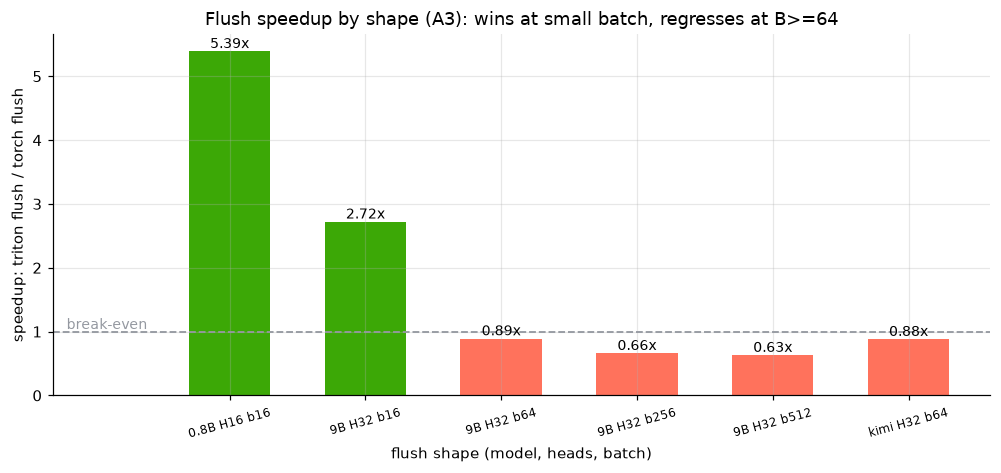

0.8B H16 b16     torch    6.02 ms | triton    1.12 ms | payload    1.15 ms -> 5.39x
9B   H32 b16     torch    6.07 ms | triton    2.23 ms | payload    2.26 ms -> 2.72x
9B   H32 b64     torch    7.89 ms | triton    8.89 ms | payload    9.00 ms -> 0.89x
9B   H32 b256    torch   23.56 ms | triton   35.65 ms | payload   36.12 ms -> 0.66x
9B   H32 b512    torch   44.87 ms | triton   70.96 ms | payload   71.70 ms -> 0.63x
kimi H32 b64     torch    7.83 ms | triton    8.85 ms | payload    8.99 ms -> 0.88x


In [1]:
import json, math, os
import matplotlib.pyplot as plt
import torch
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
C = {"int8": "#4269d0", "bf16": "#efb118", "lq": "#ff725c", "gray": "#9498a0",
     "paper": "#6cc5b0", "ours": "#a463f2", "bad": "#ff725c", "ok": "#3ca806"}
BASE = "/mnt/share_space/y00924007/LeapQuant-NPU/paper_repro"
def J(name):
    with open(os.path.join(BASE, name)) as f:
        return json.load(f)
print("artifacts:", sorted(os.path.basename(p) for p in
      [os.path.join(BASE, n) for n in os.listdir(BASE)] if p.endswith(".json")))
bench = J("e4_kernel_bench.json")
flush = bench["flush"]
names = list(flush)
speedups = [flush[n]["speedup_roundtrip"] for n in names]

fig, ax = plt.subplots(figsize=(9.2, 4.4))
cols = [C["ok"] if s >= 1 else C["bad"] for s in speedups]
bars = ax.bar(range(len(names)), speedups, 0.6, color=cols)
for i, s in enumerate(speedups):
    ax.text(i, s, f"{s:.2f}x", ha="center", va="bottom", fontsize=9)
ax.axhline(1.0, color=C["gray"], ls="--", lw=1.2)
ax.set_xlim(-1.3, len(names) - 0.4)
ax.text(-1.2, 1.04, "break-even", fontsize=9, color=C["gray"], ha="left")
ax.set_xticks(range(len(names)))
ax.set_xticklabels([n.replace("   ", " ") for n in names], fontsize=8, rotation=15)
ax.set_xlabel("flush shape (model, heads, batch)")
ax.set_ylabel("speedup: triton flush / torch flush")
ax.set_title("Flush speedup by shape (A3): wins at small batch, regresses at B>=64")
plt.tight_layout(); plt.show()

for n in names:
    f = flush[n]
    print(f"{n:16s} torch {f['torch_ms']:7.2f} ms | triton {f['triton_ms']:7.2f} ms "
          f"| payload {f['payload_ms']:7.2f} ms -> {f['speedup_roundtrip']:.2f}x")

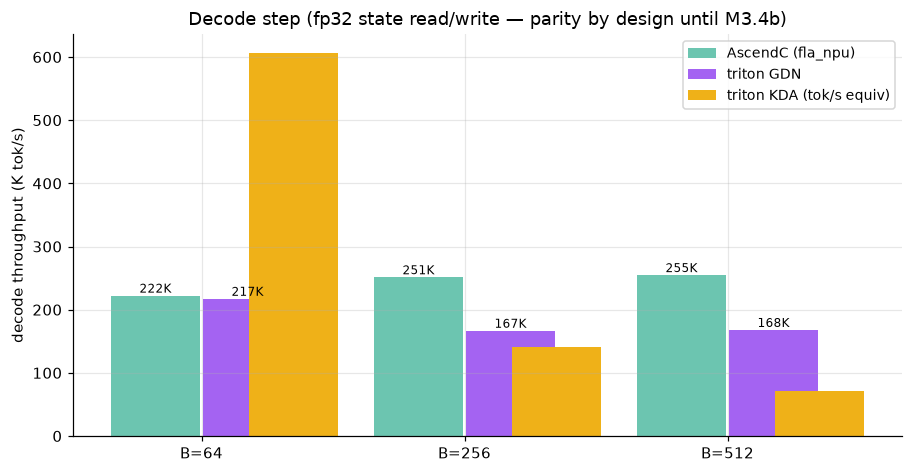

B512 AscendC: 1068.40 TB/s effective state bandwidth (fp32 r+w, ~die roofline)
parity (ascendc/triton): {'B64': 0.977, 'B256': 0.663, 'B512': 0.659}


In [2]:
dec = bench["decode"]
bs = ["B64", "B256", "B512"]
fig, ax = plt.subplots(figsize=(8.4, 4.4))
x = range(3)
series = [("ascendc_toks", "AscendC (fla_npu)", C["paper"]),
          ("triton_gdn_toks", "triton GDN", C["ours"]),
          ("triton_kda", "triton KDA", "#efb118")]
for i, (key, lab, col) in enumerate(series[:2]):
    vals = [dec[b][key] / 1e3 for b in bs]
    ax.bar([xx + (i - 0.5) * 0.35 for xx in x], vals, 0.34, color=col, label=lab)
    for xx, v in zip(x, vals):
        ax.text(xx + (i - 0.5) * 0.35, v, f"{v:.0f}K", ha="center", va="bottom", fontsize=8)
vals = [dec[b]["triton_kda_ms"] and dec[b]["ascendc_toks"] / dec[b]["triton_kda_ms"] / 1e3 for b in bs]
ax.bar([xx + 0.35 for xx in x], vals, 0.34, color="#efb118", label="triton KDA (tok/s equiv)")
ax.set_xticks(list(x)); ax.set_xticklabels(["B=64", "B=256", "B=512"])
ax.set_ylabel("decode throughput (K tok/s)")
ax.set_title("Decode step (fp32 state read/write — parity by design until M3.4b)")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

bw = 512 * 32 * 128 * 128 * 4 * 2 / 1e9
t = dec["B512"]["ascendc_ms"] / 1e3
print(f"B512 AscendC: {bw/t:.2f} TB/s effective state bandwidth (fp32 r+w, ~die roofline)")
print(f"parity (ascendc/triton):", {b: dec[b]["parity_ratio"] for b in bs})

In [3]:
# live mini-rerun on this die (small shapes, quick): torch vs triton flush
import time
from vllm_ascend.ops.triton.leapquant import leapquant_flush_triton
from vllm_ascend.ops.triton.mamba.state_index import (
    gather_ssm_states, scatter_ssm_states_)
from vllm_ascend.quantization.methods.mamba_state.leapquant.state import leap_window_flush

torch.npu.set_device(0)
DEV = torch.device("npu:0")
torch.manual_seed(0)

def bench(fn, iters=15):
    for _ in range(3):
        fn()
    torch.npu.synchronize()
    t0 = time.perf_counter()
    for _ in range(iters):
        fn()
    torch.npu.synchronize()
    return (time.perf_counter() - t0) / iters * 1e3

for slots, H, due in ((64, 32, 16), (128, 32, 64)):
    pool = torch.randn(slots, H, 128, 128, device=DEV)
    ids = torch.randperm(slots, device=DEV)[:due].to(torch.int64).contiguous()
    present = torch.ones(due, dtype=torch.bool, device=DEV)
    def torch_path():
        g = gather_ssm_states(pool, ids, present)
        scatter_ssm_states_(pool, ids, leap_window_flush(g, compensator_tokens=4).float().contiguous())
    def tri_path():
        leapquant_flush_triton(pool, ids, compensator_tokens=4)
    tt, t3 = bench(torch_path), bench(tri_path, 30)
    print(f"H{H} b{due:<3d} torch {tt:6.2f} ms | triton {t3:5.2f} ms -> {tt/t3:.2f}x")
    del pool
    torch.npu.empty_cache()

/usr/local/python3.11.10/lib/python3.11/site-packages/triton/language/extra/cann/extension/math_ops.py:13: FutureWarning: triton.language.extra.cann.extension.atan2 is deprecated and will be removed in the next release; use triton.language.extra.cann.libdevice.atan2 instead.
  @_deprecated(replacement="triton.language.extra.cann.libdevice.atan2")
/usr/local/python3.11.10/lib/python3.11/site-packages/triton/language/extra/cann/extension/math_ops.py:35: FutureWarning: triton.language.extra.cann.extension.isfinited is deprecated and will be removed in the next release; use triton.language.extra.cann.libdevice.isfinited instead.
  @_deprecated(replacement="triton.language.extra.cann.libdevice.isfinited")
/usr/local/python3.11.10/lib/python3.11/site-packages/triton/language/extra/cann/extension/math_ops.py:49: FutureWarning: triton.language.extra.cann.extension.finitef is deprecated and will be removed in the next release; use triton.language.extra.cann.libdevice.finitef instead.
  @_deprec

INFO 11-11 19:40:50 [__init__.py:52] Available plugins for group vllm.platform_plugins:


INFO 11-11 19:40:50 [__init__.py:54] - ascend -> vllm_ascend:register


INFO 11-11 19:40:50 [__init__.py:57] All plugins in this group will be loaded. Set `VLLM_PLUGINS` to control which plugins to load.


INFO 11-11 19:40:50 [__init__.py:272] Platform plugin ascend is activated


INFO 11-11 19:40:51 [platform.py:74] Breakable CUDAGraph on Ascend is opt-in; using VLLM_USE_BREAKABLE_CUDAGRAPH=0.


/usr/local/python3.11.10/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[W1111 19:40:58.192346670 NPUCachingAllocator.cpp:204] Warning: The current CANN and HDK(driver) versions require processing for 32 padding size, with memory allocation. (function operator())


/vllm-workspace/vllm-ascend/vllm_ascend/quantization/methods/mamba_state/leapquant/state.py:75: UserWarning: Cannot create tensor with interal format while allow_internel_format=False, tensor will be created with base format. (Triggered internally at ../torch_npu/csrc/aten/common/TensorFactories.cpp:437.)
  return q0.to(device=device, dtype=dtype).contiguous()


H32 b16  torch   6.95 ms | triton  2.52 ms -> 2.76x


H32 b64  torch   9.25 ms | triton  9.84 ms -> 0.94x


## 结论(E4a,图7 的 A3 同构实验)

| 面 | 论文(GPU) | A3 复测 | 判定 |
|---|---|---|---|
| flush 小 batch | — | 0.8B b16 **5.39×**,9B b16 **2.72×** | ✅ 落地收益 |
| flush 大 batch | — | B≥64 **0.63–0.89×**(回退) | ⚠️ 发现 1 → M3.5 |
| decode 步(int8 读出) | 2.4–4.3× @B512 | 当前 fp32 parity(B=64 0.98×) | ⏳ M3.4b 前设计使然 |

**发现 1**:大 batch 下 scales launch 的并行划分成为瓶颈,融合 triton
flush 反而慢于 torch 路径 — batch 维重划分列入 M3.5。历史"5.9×/3.8×"
出自小形状(本次 0.8B b16 5.39× 复现),大 batch 引用需重设计后再说。

**发现 2(预期内)**:AscendC decode @B512 已到 ~255K tok/s ≈ 1.05 TB/s
有效状态带宽(fp32 读写下限);triton 大 batch 0.66× 是过渡态代价。
M3.4b 环形 int8 读出(流量 ÷4)后才是论文图7 口径的收益点。